# ANA-073 — What supplies the apparent epistasis?
RUN-188 compares independently refitted profile-additive sigmoid (r=0) and
full pairwise sigmoid (selected r=0.5) landscapes under the same frozen noise law.
The intrinsic layer is after the sigmoid: even r=0 can have nonzero Walsh
interaction power, but a monotone sigmoid cannot create sign reversals.

We audit the archived results, then separate the *existing* synthetic observations
into intrinsic F, shared error C and independent errors e1/e2. No fitting or
new random draws are performed. Intermediate layers remove a known saved error
component; they are post-fit diagnostic ablations, not newly calibrated models.
Eight originally fresh seeds are primary; all 24 are exported. These seeds and
empirical panels have already been inspected. Dots and 10–90% ranges describe
generator/panel variation, not confidence intervals or biological replication.

In [1]:
from pathlib import Path
import hashlib, json, sys, sqlite3, importlib.util, importlib.metadata
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from scipy.linalg import hadamard
from IPython.display import display
import yaml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'labproject.yaml').exists())
ANA = ROOT/'analyses/2026-11-25_ANA-073_run-188-structured-interactions-versus-observation-randomness'
BUNDLE = ROOT/'data/processed/aggregate-thermodynamic-gnk-calibration/RUN-188'
OUT = BUNDLE/'outputs'
FROZEN = BUNDLE/'frozen_runtime'
BASE = FROZEN/'baseline/RUN-186'
FIG, TAB = ANA/'figures', ANA/'tables'
FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
def dump(p,v): p.write_text(json.dumps(v,indent=2,allow_nan=False)+'\n')
EXPECTED = 'c40c6d47a7814bd149d07735254a2ce69cd1d70c6ae33058988a0470e9d8c306'
assert sha(OUT/'manifest.json')==EXPECTED
manifest=json.loads((OUT/'manifest.json').read_text())
for name,digest in manifest['files'].items(): assert sha(OUT/name)==digest,name
runtime=json.loads((BUNDLE/'records/interaction_ablation_runtime.json').read_text())
assert sha(FROZEN/'prelaunch_manifest.json')==runtime['manifest_sha256']
frozen_manifest=json.loads((FROZEN/'prelaunch_manifest.json').read_text())
for name,digest in frozen_manifest['files'].items(): assert sha(FROZEN/name)==digest,name
for name in ['labproj-exit-code.txt','interaction-ablation-scientific-exit-code.txt']:
    assert (BUNDLE/'logs'/name).read_text().strip()=='0'
assert not (BUNDLE/'logs/stderr.txt').read_text()
settings=json.loads((OUT/'selected_parameters.json').read_text())
audit=pd.read_csv(OUT/'seed_audit.csv'); assert len(audit)==24
fresh=audit[audit.cohort=='fresh'].seed.tolist(); assert len(fresh)==8
config=yaml.safe_load((OUT/'config.yaml').read_text())
scale=settings[0]['calibration_scale']; resolutions=np.array([0,.001,.01])*scale
eps=resolutions[1]; cutoffs=np.array([.05396940664223584,.05369397352521348])
fit_rows=[]
for s in settings:
    con=sqlite3.connect(f'file:{OUT}/fits/{s["arm"]}.sqlite3?mode=ro',uri=True)
    assert dict(con.execute('select state,count(*) from trials group by state'))=={'COMPLETE':11712}
    best=con.execute('select min(value) from trial_values').fetchone()[0]
    np.testing.assert_allclose(best,s['objective']['total'],rtol=1e-13)
    con.close()
    fit_rows.append(dict(arm=s['arm'],r=s['ratio'],selected_trial=s['selected_trial'],**s['objective']))
fits=pd.DataFrame(fit_rows).set_index('arm');fits.to_csv(TAB/'calibration.csv')
assert fits.loc['r0','r']==0 and fits.loc['full','r']==.5
previous=json.loads((BASE/'outputs/selected_parameters.json').read_text())
prior=next(s for s in previous if s['observation']=='shared_stop_sensitivity')
np.testing.assert_array_equal(settings[1]['parameters'],prior['parameters'])
assert settings[1]['ratio']==prior['ratio']
display(fits)
print('Authenticated outputs:',len(manifest['files']),'frozen payloads:',len(frozen_manifest['files']))

,r,selected_trial,quantile,mean_sd,floor_cdf,total
arm,,,,,,
r0,0.0,0,0.041241,0.000814,0.000020,0.042075
full,0.5,1,0.029890,0.001101,0.000004,0.030995


Authenticated outputs: 41 frozen payloads: 460


## Recompute the diagnostics independently
A Walsh coefficient is a signed contrast of 16 fitness values divided by 16.
Absolute order-k power is the sum of squared coefficients with k sites.
Cross-replicate power uses coefficient products instead of squares; it removes
independent zero-mean error only *in expectation*. Shared error survives.
Negative cross-powers and stop-adjusted powers are retained.

A repeatable sign reversal requires the same mutation and the same two directed
edge signs in both replicates. The threshold is 0.001 × the fixed calibration
scale. Strata for intermediate noise layers are held at their arm's observed
activity labels, avoiding selection changes within a noise-removal comparison.
Between arms, activity strata can have different membership and coverage.

In [2]:
H=hadamard(16).astype(float); orders=np.array([i.bit_count() for i in range(16)])
faces=np.array([[s,s|1<<i,s|1<<j,s|1<<i|1<<j] for i,j in combinations(range(4),2)
                for s in range(16) if not s & ((1<<i)|(1<<j))])
def switches(y,t):
    z=y[:,faces]
    edges=np.stack([z[:,:,1]-z[:,:,0],z[:,:,3]-z[:,:,2],z[:,:,2]-z[:,:,0],z[:,:,3]-z[:,:,1]],axis=-1)
    signs=np.where(edges>t,1,np.where(edges < -t,-1,0))
    flip=np.stack([signs[:,:,0]*signs[:,:,1]<0,signs[:,:,2]*signs[:,:,3]<0],axis=-1)
    return signs,flip

def calculate(a,b,q,labels,activity):
    c1,c2=a@H/16,b@H/16; cm=(c1+c2)/2
    active_n=activity.sum(axis=1)
    cubes=pd.DataFrame(dict(cube=np.arange(len(a)),active_nodes=active_n,
        stratum=np.where(active_n==0,'no_active',np.where(active_n==16,'all_active','some_active'))))
    for k in range(1,5):
        m=orders==k
        cubes[f'mean_power_{k}']=(cm[:,m]**2).sum(axis=1)
        cubes[f'cross_power_{k}']=(c1[:,m]*c2[:,m]).sum(axis=1)
        cubes[f'stop_adjusted_power_{k}']=cubes[f'cross_power_{k}']-m.sum()*np.broadcast_to(q,a.shape).sum(axis=1)/256
    np.testing.assert_allclose(cubes[[f'mean_power_{k}' for k in range(1,5)]].sum(axis=1),((a+b)/2).var(axis=1),atol=1e-20,rtol=1e-10)
    counts=activity[:,faces].sum(axis=-1)
    ft=[]
    for t in resolutions:
        sa,fa=switches(a,t); sb,fb=switches(b,t); _,fm=switches((a+b)/2,t)
        same=np.stack([(sa[:,:,:2]==sb[:,:,:2]).all(axis=-1),(sa[:,:,2:]==sb[:,:,2:]).all(axis=-1)],axis=-1)
        repeated=fa&fb&same
        ft.append(pd.DataFrame(dict(cube=np.repeat(np.arange(len(a)),24),face=np.tile(np.arange(24),len(a)),
            epsilon=t,active_vertices=counts.ravel(),stratum=np.where(counts==0,'no_active',np.where(counts==4,'all_active','some_active')).ravel(),
            mean_sign=fm.any(axis=-1).ravel(),mean_reciprocal=fm.all(axis=-1).ravel(),
            reproducible_sign=repeated.any(axis=-1).ravel(),reproducible_reciprocal=repeated.all(axis=-1).ravel())))
    f=pd.concat(ft,ignore_index=True)
    for tab in [cubes,f]:
        for k,v in labels.items():tab[k]=v
    return cubes,f

# Independent known-answer controls, including a negative cross-power estimate.
y=2*H[1]+3*H[3]+1
c,f=calculate(y[None],y[None],0,{},np.ones((1,16),bool))
assert c.mean_power_1.item()==4 and c.mean_power_2.item()==9 and c.mean_power_3.item()==0
_,f=calculate(H[3][None],-H[3][None],0,{},np.ones((1,16),bool))
assert not f.reproducible_sign.any()
x=H[1]+2*H[2]+3*H[4]+4*H[8]+1; y=1/(1+np.exp(-x))
c,f=calculate(y[None],y[None],0,{},np.ones((1,16),bool))
assert c.mean_power_3.item()>0 and not f.mean_sign.any()

## Recover the exact sampled errors, without drawing again
Y1 = F + C + e1 and Y2 = F + C + e2. The two-replicate mean is
Ybar = F + C + (e1+e2)/2. The shared component C can be reconstructed exactly
from the archived stop donors, saved depth and original uniform variates.
These uniforms are regenerated from their recorded seed, not newly sampled.
The independent-only and shared-only layers below retain the fitted readout.

In [3]:
# Use only the frozen restoration and observation functions for replay; statistics
# above are independently implemented, not imported from the RUN's metric module.
sys.path.insert(0,str(FROZEN/'source/scripts'))
import interaction_ablation_exp065 as replay
noise,donors=replay.restore_noise(BASE/'outputs')
spec=importlib.util.spec_from_file_location('frozen_observation',BASE/'frozen_runtime/source/scripts/replicate_observation_exp065.py')
obs=importlib.util.module_from_spec(spec);spec.loader.exec_module(obs)
CUBES=[];FACES=[];DECOMP=[];CREATED=[];replay_errors=[]
with np.load(OUT/'empirical_replicates.npz') as z:
    a,b,q=z['replicate_1'],z['replicate_2'],z['shared_covariance']
    activity=(a>cutoffs[0])&(b>cutoffs[1])
    c,f=calculate(a,b,q,dict(arm='empirical',seed=-1,cohort='empirical',layer='observed'),activity)
    CUBES.append(c);FACES.append(f)
for row in audit.itertuples(index=False):
    with np.load(OUT/'confirmation'/f'TrpB_{row.seed}.npz') as z:
        codes=z['genotypes'];ix=np.ravel_multi_index(codes.reshape(-1,4).T,(20,)*4)
        u=np.random.default_rng(int(row.noise_seed)).random((160000,6))[ix].reshape(-1,16,6)
        for arm in ['r0','full']:
            intrinsic=z[f'{arm}_intrinsic'];a=z[f'{arm}_replicate_1'];b=z[f'{arm}_replicate_2']
            depth=z[f'{arm}_input_depth'];q=z[f'{arm}_shared_covariance']
            aa,bb,dd,qq=obs.observe(intrinsic,noise,u,shared=True)
            for actual,expected in [(aa,a),(bb,b),(dd,depth),(qq,q)]:
                np.testing.assert_allclose(actual,expected,rtol=1e-12,atol=1e-14)
            replay_errors.append(float(max(np.abs(aa-a).max(),np.abs(bb-b).max())))
            bins=np.searchsorted(noise['depth_breaks'],depth,side='right');common=np.zeros_like(intrinsic)
            for k in range(4):
                take=bins==k;pool=noise['common'][k]
                common[take]=pool[np.minimum((u[:,:,5][take]*len(pool)).astype(int),len(pool)-1)]
            aind,bind,_,_=obs.observe(intrinsic,noise,u,shared=False)
            np.testing.assert_allclose(a-common,aind,rtol=1e-12,atol=1e-14)
            np.testing.assert_allclose(b-common,bind,rtol=1e-12,atol=1e-14)
            activity=(a>cutoffs[0])&(b>cutoffs[1])
            for layer,first,second,cov in [('intrinsic',intrinsic,intrinsic,0),('independent_only',a-common,b-common,0),
                    ('shared_only',intrinsic+common,intrinsic+common,q),('observed',a,b,q)]:
                c,f=calculate(first,second,cov,dict(arm=arm,seed=row.seed,cohort=row.cohort,layer=layer),activity)
                CUBES.append(c);FACES.append(f)
            fcoef=intrinsic@H/16;ccoef=common@H/16;ecoef=(((a+b)/2)-intrinsic-common)@H/16
            for k in range(1,5):
                m=orders==k
                fp=(fcoef[:,m]**2).sum(axis=1);cp=(ccoef[:,m]**2).sum(axis=1);ep=(ecoef[:,m]**2).sum(axis=1)
                fc=2*(fcoef[:,m]*ccoef[:,m]).sum(axis=1)
                fe=2*(fcoef[:,m]*ecoef[:,m]).sum(axis=1)
                ce=2*(ccoef[:,m]*ecoef[:,m]).sum(axis=1)
                total=((((a+b)/2)@H/16)[:,m]**2).sum(axis=1)
                np.testing.assert_allclose(fp+cp+ep+fc+fe+ce,total,rtol=1e-11,atol=1e-20)
                for cube in range(len(a)):
                    DECOMP.append(dict(arm=arm,seed=row.seed,cohort=row.cohort,cube=cube,order=k,
                        intrinsic=fp[cube],shared=cp[cube],independent_mean=ep[cube],cross_fc=fc[cube],
                        cross_fe=fe[cube],cross_ce=ce[cube],cross_total=fc[cube]+fe[cube]+ce[cube],observed=total[cube]))
            for t in resolutions:
                _,si=switches(intrinsic,t);_,so=switches((a+b)/2,t)
                si=si.any(axis=-1);so=so.any(axis=-1)
                CREATED.append(dict(arm=arm,seed=row.seed,cohort=row.cohort,epsilon=t,
                    intrinsic_sign_fraction=si.mean(),observed_sign_fraction=so.mean(),
                    noise_created_fraction_of_faces=(so&~si).mean(),
                    observed_signs_absent_intrinsically=(so&~si).sum()/so.sum() if so.any() else np.nan,
                    intrinsic_signs_removed_fraction_of_faces=(si&~so).mean()))
cubes=pd.concat(CUBES,ignore_index=True);faces_table=pd.concat(FACES,ignore_index=True)
decomp=pd.DataFrame(DECOMP);created=pd.DataFrame(CREATED)
cubes.to_csv(TAB/'cube_powers_recomputed.csv.gz',index=False)
faces_table.to_csv(TAB/'face_signs_recomputed.csv.gz',index=False)
decomp.to_csv(TAB/'power_decomposition.csv.gz',index=False);created.to_csv(TAB/'noise_created_signs.csv',index=False)

# Verify original observed and intrinsic powers and observed face metrics.
oldc=pd.read_csv(OUT/'cube_powers.csv.gz',float_precision='round_trip');oldf=pd.read_csv(OUT/'face_reproducibility.csv.gz',float_precision='round_trip')
keys=['arm','seed','layer','cube'];powercols=[f'{method}_power_{k}' for method in ['mean','cross','stop_adjusted'] for k in range(1,5)]
for layer in ['intrinsic','observed']:
    x=cubes[cubes.layer==layer].set_index(keys).sort_index();y=oldc[oldc.layer==layer].set_index(keys).sort_index()
    np.testing.assert_allclose(x[powercols],y[powercols],rtol=1e-10,atol=1e-18)
keys=['arm','seed','layer','epsilon','cube','face']; cols=['mean_sign','mean_reciprocal','reproducible_sign','reproducible_reciprocal']
x=faces_table[faces_table.layer=='observed'].set_index(keys).sort_index();y=oldf[oldf.layer=='observed'].set_index(keys).sort_index()
assert x.index.equals(y.index)
np.testing.assert_array_equal(x[cols],y[cols])
print('Replayed 48 paired synthetic observations. Maximum absolute discrepancy:',max(replay_errors))
print('Independently reproduced all original cube powers and observed face classifications.')

Replayed 48 paired synthetic observations. Maximum absolute discrepancy: 0.0
Independently reproduced all original cube powers and observed face classifications.


In [4]:
# Summaries retain every seed, negative powers and empty strata.
strata=['all','no_active','some_active','all_active']; summary=[]
for label,c in cubes.groupby(['arm','seed','cohort','layer'],sort=False):
    arm,seed,cohort,layer=label
    f=faces_table[(faces_table.arm==arm)&(faces_table.seed==seed)&(faces_table.layer==layer)]
    for st in strata:
        cc=c if st=='all' else c[c.stratum==st]
        for t in resolutions:
            ff=f[np.isclose(f.epsilon,t,rtol=0,atol=1e-15)]
            if st!='all':ff=ff[ff.stratum==st]
            item=dict(arm=arm,seed=seed,cohort=cohort,layer=layer,stratum=st,epsilon=t,n_cubes=len(cc),n_faces=len(ff))
            item.update({n:cc[n].mean() for n in powercols})
            item.update({n:ff[n].mean() for n in cols})
            for method in ['mean','cross','stop_adjusted']:
                total=cc[[f'{method}_power_{k}' for k in range(1,5)]].sum().sum()
                for name,ks in [('epistatic',[2,3,4]),('higher_order',[3,4])]:
                    p=cc[[f'{method}_power_{k}' for k in ks]].sum().sum()
                    item[f'{method}_{name}_fraction']=p/total if len(cc) and total>len(cc)*1e-18 else np.nan
            summary.append(item)
summary=pd.DataFrame(summary);summary.to_csv(TAB/'seed_layer_stratum_summary.csv',index=False)
primary=summary[np.isclose(summary.epsilon,eps,rtol=0,atol=1e-15)]
fresh_summary=primary[primary.cohort=='fresh'];emp=primary[primary.arm=='empirical'].set_index('stratum')
cohort_summary=[]
for labels,g in summary.groupby(['arm','cohort','layer','stratum','epsilon']):
    for name in powercols+cols+['mean_epistatic_fraction','mean_higher_order_fraction']:
        v=g[name].dropna()
        cohort_summary.append(dict(zip(['arm','cohort','layer','stratum','epsilon'],labels),metric=name,
            n_seeds=len(g),n_available=len(v),median=v.median(),q10=v.quantile(.1),q90=v.quantile(.9)))
pd.DataFrame(cohort_summary).to_csv(TAB/'cohort_summary.csv',index=False)
# Matched-seed differences in absolute error; negative means the full arm is closer.
paired=[]
for st in strata:
    for metric in ['cross_power_2','cross_power_3','cross_power_4','reproducible_sign','reproducible_reciprocal']:
        target=emp.loc[st,metric]
        g=primary[(primary.layer=='observed')&(primary.stratum==st)&(primary.arm!='empirical')]
        wide=g.pivot(index=['seed','cohort'],columns='arm',values=metric)
        for (seed,cohort),v in wide.iterrows():
            paired.append(dict(seed=seed,cohort=cohort,stratum=st,metric=metric,empirical=target,
                r0=v.r0,full=v.full,full_minus_r0=v.full-v.r0,
                absolute_error_change=abs(v.full-target)-abs(v.r0-target)))
paired=pd.DataFrame(paired);paired.to_csv(TAB/'paired_model_contrasts.csv',index=False)
paired_summary=paired.groupby(['cohort','stratum','metric']).agg(
    n=('absolute_error_change','count'),full_closer=('absolute_error_change',lambda x:int((x<0).sum())),
    median_error_change=('absolute_error_change','median'),median_change=('full_minus_r0','median')).reset_index()
paired_summary.to_csv(TAB/'paired_error_summary.csv',index=False)
# Explicit coverage: cube and face classifications have different denominators.
coverage=primary[(primary.layer=='observed')].groupby(['arm','cohort','stratum'])[['n_cubes','n_faces']].sum()
coverage.to_csv(TAB/'activity_coverage.csv')
display(fresh_summary[fresh_summary.stratum=='all'].groupby(['arm','layer'])[['mean_sign','reproducible_sign','cross_power_2','cross_power_3','cross_power_4']].median())

mean_sign  reproducible_sign  cross_power_2  \
arm  layer                                                           
full independent_only   0.601562           0.158854       0.000268   
     intrinsic          0.098958           0.098958       0.000248   
     observed           0.640625           0.398438       0.000322   
     shared_only        0.627604           0.627604       0.000310   
r0   independent_only   0.648438           0.166667       0.000306   
     intrinsic          0.000000           0.000000       0.000292   
     observed           0.625000           0.429688       0.000396   
     shared_only        0.627604           0.627604       0.000394   

                       cross_power_3  cross_power_4  
arm  layer                                           
full independent_only       0.000059   5.246726e-06  
     intrinsic              0.000060   3.565446e-06  
     observed               0.000142   2.325783e-05  
     shared_only            0.000148   2.341479e-05  
r0   independent_only       0.000075   3.823063e-06  
     intrinsic              0.000072   2.117880e-07  
     observed               0.000129   2.340743e-05  
     shared_only            0.000136   2.212602e-05

## Figures
Blue: independently refitted r=0. Orange: independently refitted r=0.5.
Black dashed lines are the 32 empirical confirmation cubes. There is no fitted
correspondence between individual synthetic and empirical interactions.

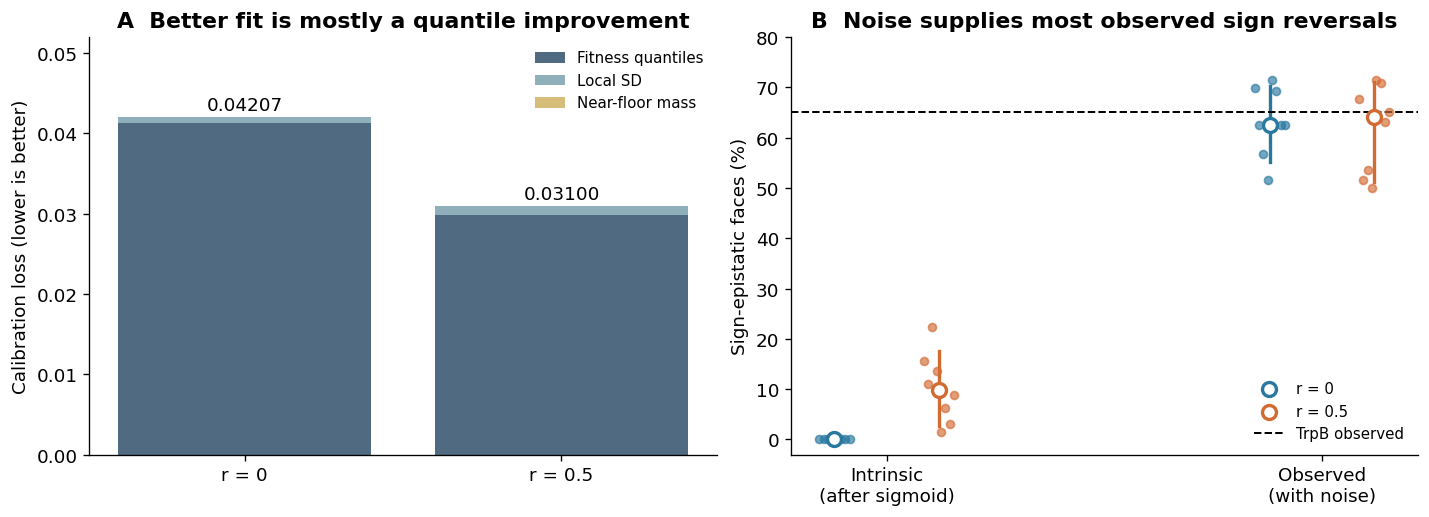

In [5]:
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
    'figure.dpi':120,'savefig.dpi':180,'pdf.fonttype':42,'axes.titleweight':'bold'})
colors={'r0':'#2878A0','full':'#D16B32'};names={'r0':'r = 0','full':'r = 0.5'}
def save(fig,name):
    fig.savefig(FIG/f'{name}.png',bbox_inches='tight');fig.savefig(FIG/f'{name}.pdf',bbox_inches='tight')
    display(fig);plt.close(fig)
def points(ax,values,x,color,label=None,marker='o'):
    v=np.asarray(values,float);v=v[np.isfinite(v)]
    if not len(v):return
    ax.scatter(x+np.linspace(-.035,.035,len(v)),v,s=23,color=color,alpha=.65,zorder=3)
    lo,mid,hi=np.quantile(v,[.1,.5,.9]);ax.plot([x,x],[lo,hi],color=color,lw=2)
    ax.scatter([x],[mid],marker=marker,s=70,facecolor='white',edgecolor=color,lw=2,zorder=4,label=label)

fig,axs=plt.subplots(1,2,figsize=(11.8,4.2),layout='constrained')
bottom=np.zeros(2)
for metric,label,color in [('quantile','Fitness quantiles','#506A82'),('mean_sd','Local SD','#8FAFBA'),('floor_cdf','Near-floor mass','#D6BE7A')]:
    vals=fits.loc[['r0','full'],metric].to_numpy();axs[0].bar([0,1],vals,bottom=bottom,color=color,label=label);bottom+=vals
for i,v in enumerate(bottom):axs[0].text(i,v+.0008,f'{v:.5f}',ha='center')
axs[0].set(xticks=[0,1],xticklabels=['r = 0','r = 0.5'],ylabel='Calibration loss (lower is better)',ylim=(0,.052),title='A  Better fit is mostly a quantile improvement')
axs[0].legend(frameon=False,fontsize=9,loc='upper right')
for arm,dx in [('r0',-.12),('full',.12)]:
    g=fresh_summary[(fresh_summary.arm==arm)&(fresh_summary.stratum=='all')]
    for i,layer in enumerate(['intrinsic','observed']):points(axs[1],100*g[g.layer==layer].mean_sign,i+dx,colors[arm],names[arm] if i==0 else None)
axs[1].axhline(100*emp.loc['all','mean_sign'],color='black',ls='--',lw=1.2,label='TrpB observed')
axs[1].set(xticks=[0,1],xticklabels=['Intrinsic\n(after sigmoid)','Observed\n(with noise)'],ylabel='Sign-epistatic faces (%)',ylim=(-3,80),title='B  Noise supplies most observed sign reversals')
axs[1].legend(frameon=False,fontsize=9,loc='lower right')
save(fig,'01_calibration_and_sign_epistasis')

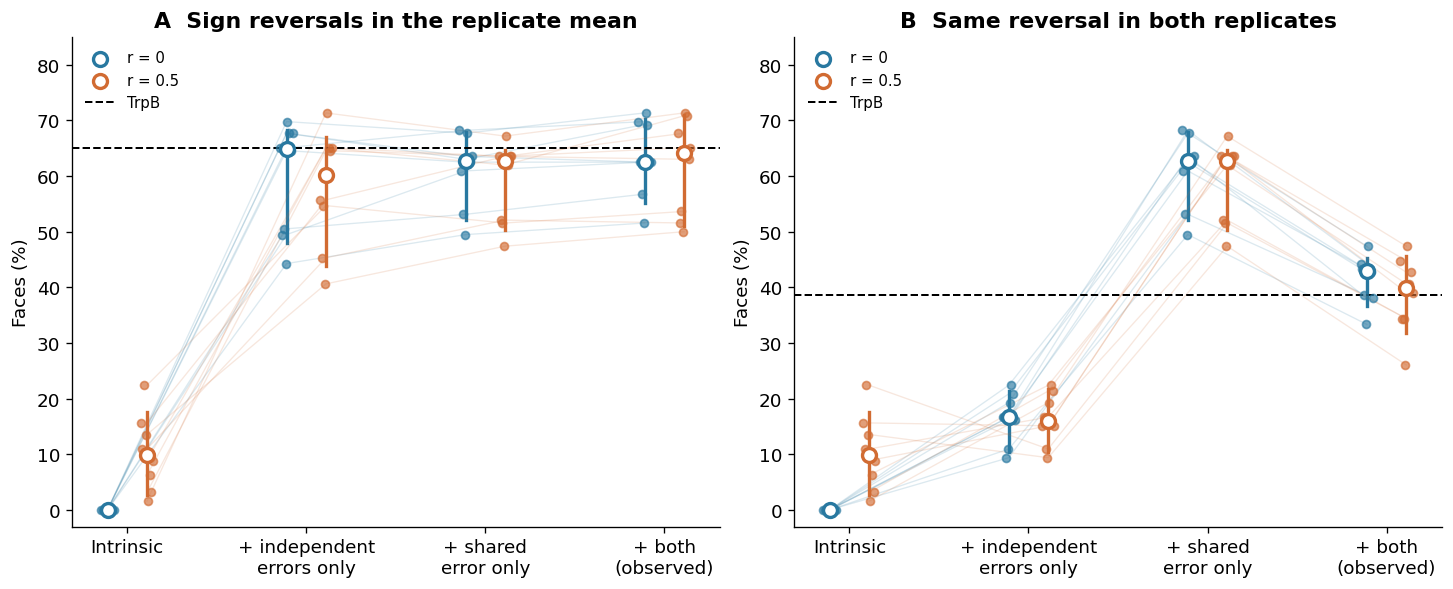

In [6]:
fig,axs=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
layers=['intrinsic','independent_only','shared_only','observed'];labels=['Intrinsic','+ independent\nerrors only','+ shared\nerror only','+ both\n(observed)']
for ax,metric,title in zip(axs,['mean_sign','reproducible_sign'],['A  Sign reversals in the replicate mean','B  Same reversal in both replicates']):
    for arm,dx in [('r0',-.11),('full',.11)]:
        g=fresh_summary[(fresh_summary.arm==arm)&(fresh_summary.stratum=='all')]
        for seed in fresh:
            row=g[g.seed==seed].set_index('layer').loc[layers,metric]
            ax.plot(np.arange(4)+dx,100*row,color=colors[arm],alpha=.16,lw=.8)
        for i,layer in enumerate(layers):points(ax,100*g[g.layer==layer][metric],i+dx,colors[arm],names[arm] if i==0 else None)
    ax.axhline(100*emp.loc['all',metric],color='black',ls='--',lw=1.2,label='TrpB')
    ax.set(xticks=range(4),xticklabels=labels,ylabel='Faces (%)',ylim=(-3,85),title=title)
    ax.legend(frameon=False,fontsize=9,loc='upper left')
save(fig,'02_independent_and_shared_noise')

## Exact power accounting
For each Walsh order, P(Ybar) = P(F) + P(C) + P(ebar) + cross terms.
Cross terms are 2〈F,C〉 + 2〈F,ebar〉 + 2〈C,ebar〉 in coefficient space.
They can be negative. A clean nonnegative percentage attribution is generally
impossible for a realized map. The figure shows all terms and does not call
intrinsic sigmoid-generated power latent pairwise power.

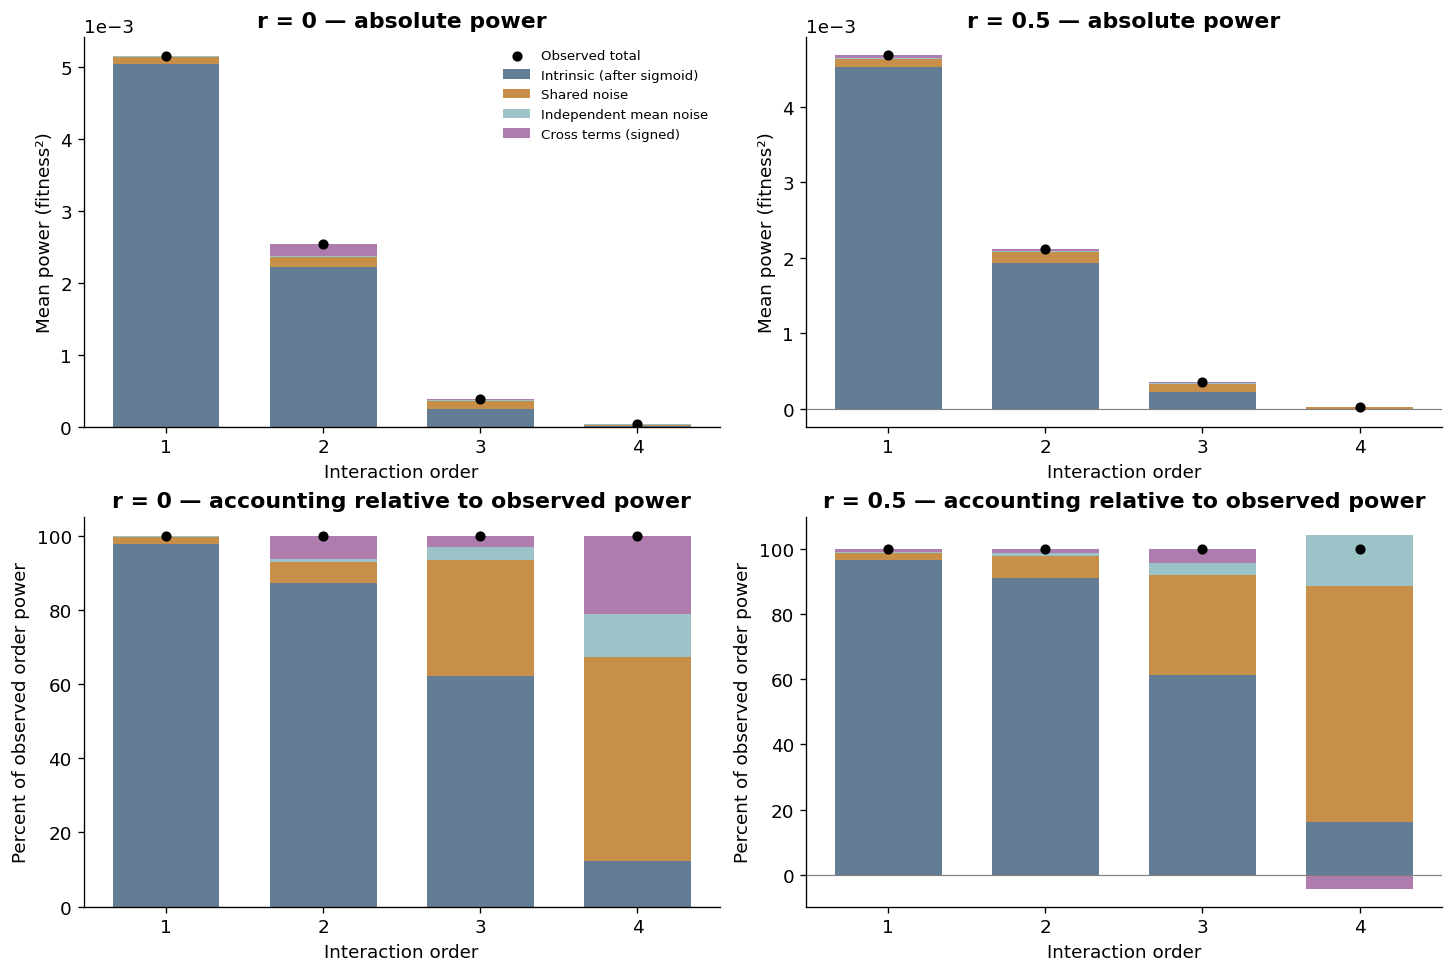

In [7]:
components=['intrinsic','shared','independent_mean','cross_total']
component_labels=['Intrinsic (after sigmoid)','Shared noise','Independent mean noise','Cross terms (signed)']
component_colors=['#637D94','#C78F49','#9CC4C8','#AF7CAE']
d=decomp[decomp.cohort=='fresh'].groupby(['arm','order'])[components+['observed']].mean()
d.to_csv(TAB/'power_budget_fresh_pooled.csv')
fig,axs=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for col,arm in enumerate(['r0','full']):
    v=d.loc[arm];x=np.arange(1,5)
    for row in range(2):
        ax=axs[row,col];pos=np.zeros(4);neg=np.zeros(4)
        for comp,label,color in zip(components,component_labels,component_colors):
            vals=v[comp].to_numpy()*(100/v.observed.to_numpy() if row else 1)
            base=np.where(vals>=0,pos,neg)
            ax.bar(x,vals,bottom=base,color=color,label=label,width=.68)
            pos+=np.maximum(vals,0);neg+=np.minimum(vals,0)
        ax.scatter(x,100*np.ones(4) if row else v.observed,color='black',s=26,zorder=5,label='Observed total')
        ax.axhline(0,color='gray',lw=.7)
        ax.set(xticks=x,xlabel='Interaction order',title=f'{names[arm]} — '+('absolute power' if row==0 else 'accounting relative to observed power'))
        if row==0:ax.ticklabel_format(axis='y',style='sci',scilimits=(0,0));ax.set_ylabel('Mean power (fitness²)')
        else:ax.set_ylabel('Percent of observed order power')
axs[0,0].legend(frameon=False,fontsize=8,loc='upper right')
save(fig,'03_exact_power_accounting')

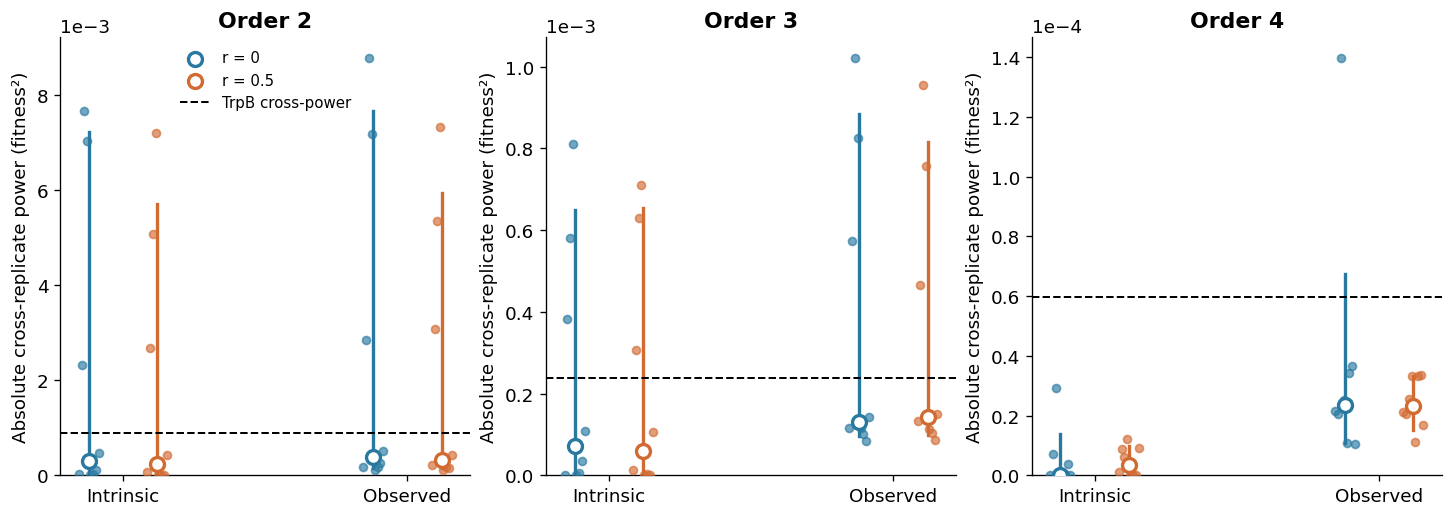

In [8]:
fig,axs=plt.subplots(1,3,figsize=(12,4.2),layout='constrained')
for ax,k in zip(axs,[2,3,4]):
    for arm,dx in [('r0',-.12),('full',.12)]:
        g=fresh_summary[(fresh_summary.arm==arm)&(fresh_summary.stratum=='all')]
        for i,layer in enumerate(['intrinsic','observed']):points(ax,g[g.layer==layer][f'cross_power_{k}'],i+dx,colors[arm],names[arm] if i==0 else None)
    ax.axhline(emp.loc['all',f'cross_power_{k}'],color='black',ls='--',lw=1.2,label='TrpB cross-power')
    ax.set(xticks=[0,1],xticklabels=['Intrinsic','Observed'],title=f'Order {k}',ylabel='Absolute cross-replicate power (fitness²)')
    ax.ticklabel_format(axis='y',style='sci',scilimits=(0,0));ax.set_ylim(bottom=0)
axs[0].legend(frameon=False,fontsize=9)
save(fig,'04_repeatable_interaction_power')

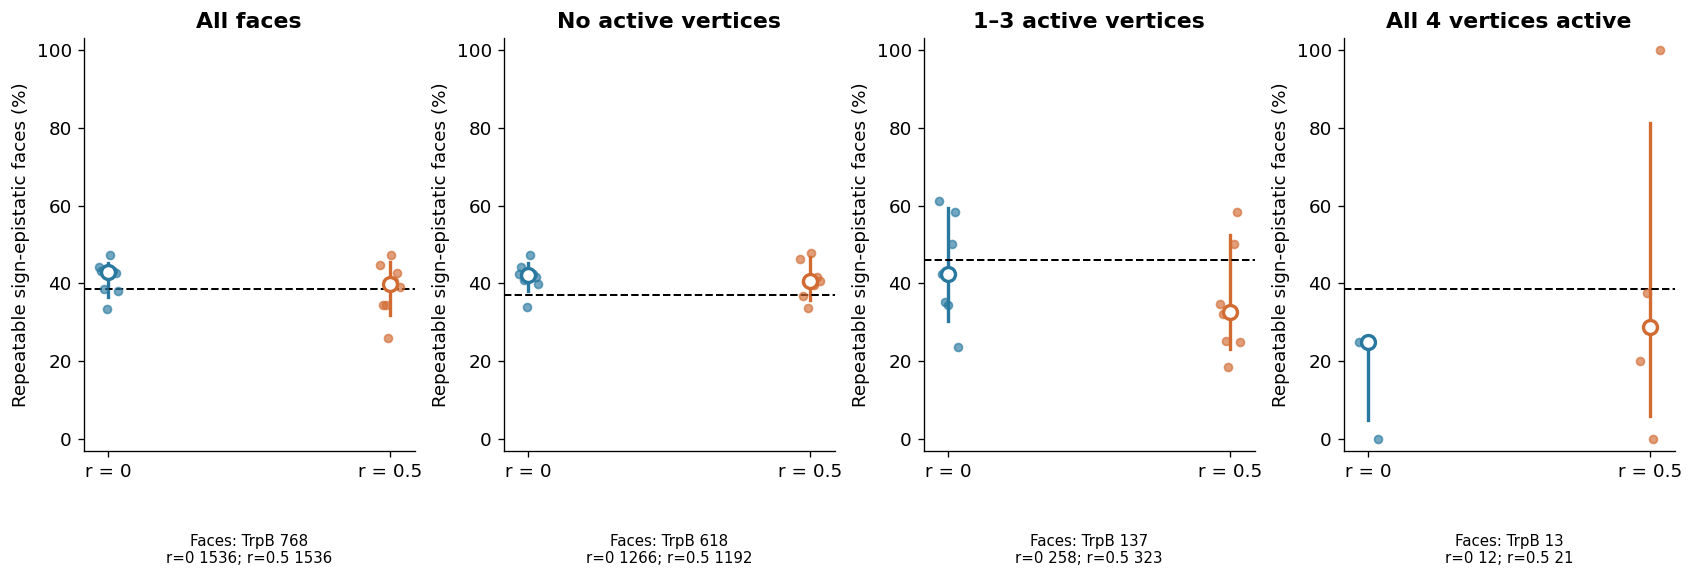

In [9]:
fig,axs=plt.subplots(1,4,figsize=(14,4.7),layout='constrained')
for ax,st,title in zip(axs,strata,['All faces','No active vertices','1–3 active vertices','All 4 vertices active']):
    counts=[]
    for i,arm in enumerate(['r0','full']):
        g=fresh_summary[(fresh_summary.arm==arm)&(fresh_summary.stratum==st)&(fresh_summary.layer=='observed')]
        points(ax,100*g.reproducible_sign,i,colors[arm],names[arm]);counts.append(int(g.n_faces.sum()))
    er=emp.loc[st];ax.axhline(100*er.reproducible_sign,color='black',ls='--',lw=1.2)
    ax.set(xticks=[0,1],xticklabels=['r = 0','r = 0.5'],ylim=(-3,103),ylabel='Repeatable sign-epistatic faces (%)',title=title)
    ax.text(.5,-.20,f'Faces: TrpB {int(er.n_faces)}\nr=0 {counts[0]}; r=0.5 {counts[1]}',ha='center',va='top',transform=ax.transAxes,fontsize=9)
save(fig,'05_activity_strata')

## Sensitivities and paired contrasts
Sparse all-active faces do not support strong conclusions; there are no all-active
16-vertex cubes in either fresh cohort or TrpB. Stop-adjusted powers below are
diagnostic sensitivities, not estimates that identify biological epistasis.
Summaries retain all resolutions, the reused cohort, signed adjusted powers and
per-seed full-minus-control absolute-error differences. The two arms also refit
readouts; their contrast is not the isolated causal effect of changing r.

In [10]:
display(paired_summary[(paired_summary.cohort=='fresh')&(paired_summary.stratum=='all')])
display(coverage)
# Compact numbers for prose, with no assertions of causal variance attribution.
report={}
for arm in ['r0','full']:
    g=fresh_summary[(fresh_summary.arm==arm)&(fresh_summary.stratum=='all')]
    report[arm]={layer:{m:float(g[g.layer==layer][m].median()) for m in ['mean_sign','reproducible_sign','reproducible_reciprocal','mean_epistatic_fraction','mean_higher_order_fraction','cross_power_2','cross_power_3','cross_power_4']} for layer in layers}
    v=created[(created.arm==arm)&(created.cohort=='fresh')&np.isclose(created.epsilon,eps,rtol=0,atol=1e-15)]
    report[arm]['observed_signs_absent_intrinsically_median']=float(v.observed_signs_absent_intrinsically.median())
report['empirical']={m:float(emp.loc['all',m]) for m in ['mean_sign','reproducible_sign','reproducible_reciprocal','mean_epistatic_fraction','mean_higher_order_fraction','cross_power_2','cross_power_3','cross_power_4']}
report['calibration_loss_reduction']=float(1-fits.loc['full','total']/fits.loc['r0','total'])
report['maximum_observation_replay_difference']=max(replay_errors)
dump(TAB/'key_numbers.json',report)
checks=dict(outputs_verified=len(manifest['files']),frozen_payloads_verified=len(frozen_manifest['files']),
    trials_verified=23424,seeds_verified=24,observation_arm_replays=48,
    maximum_observation_replay_difference=max(replay_errors),independent_cube_power_replay=True,
    independent_observed_face_classification_replay=True,exact_power_budget_identity=True,
    known_answer_controls_pass=True,full_setting_equal_RUN186=True,
    primary_seeds=8,empirical_cubes=32,refitting=False,new_random_draws=False)
dump(TAB/'validation.json',checks)
dump(TAB/'analysis_environment.json',{'python':sys.version,'packages':{n:importlib.metadata.version(n) for n in ['numpy','pandas','scipy','matplotlib','PyYAML','nbformat','nbclient','ipykernel']}})
print(json.dumps(report,indent=2))

,cohort,stratum,metric,n,full_closer,median_error_change,median_change
0,fresh,all,cross_power_2,8,2,5.055950e-05,-2.473204e-06
1,fresh,all,cross_power_3,8,7,-1.269877e-05,-1.272988e-07
2,fresh,all,cross_power_4,8,4,-1.252088e-08,-3.253381e-07
3,fresh,all,reproducible_reciprocal,8,2,5.208333e-03,-7.812500e-03
4,fresh,all,reproducible_sign,8,3,0.000000e+00,-1.302083e-02


n_cubes  n_faces
arm       cohort    stratum                      
empirical empirical all               32      768
                    all_active         0       13
                    no_active         17      618
                    some_active       15      137
full      fresh     all               64     1536
                    all_active         0       21
                    no_active         36     1192
                    some_active       28      323
          reused    all              128     3072
                    all_active         0       16
                    no_active         93     2711
                    some_active       35      345
r0        fresh     all               64     1536
                    all_active         0       12
                    no_active         40     1266
                    some_active       24      258
          reused    all              128     3072
                    all_active         0       33
                    no_active         92     2668
                    some_active       36      371

{
  "r0": {
    "intrinsic": {
      "mean_sign": 0.0,
      "reproducible_sign": 0.0,
      "reproducible_reciprocal": 0.0,
      "mean_epistatic_fraction": 0.3529506381514983,
      "mean_higher_order_fraction": 0.043953769679677526,
      "cross_power_2": 0.00029157681122349337,
      "cross_power_3": 7.213978921898463e-05,
      "cross_power_4": 2.1178802331078456e-07
    },
    "independent_only": {
      "mean_sign": 0.6484375,
      "reproducible_sign": 0.16666666666666666,
      "reproducible_reciprocal": 0.052083333333333336,
      "mean_epistatic_fraction": 0.478595874312684,
      "mean_higher_order_fraction": 0.11628757427850632,
      "cross_power_2": 0.0003064693278210669,
      "cross_power_3": 7.536650734180257e-05,
      "cross_power_4": 3.823063198899957e-06
    },
    "shared_only": {
      "mean_sign": 0.6276041666666667,
      "reproducible_sign": 0.6276041666666667,
      "reproducible_reciprocal": 0.2838541666666667,
      "mean_epistatic_fraction": 0.54205390288

## Resolution sensitivity
Sign reversals with arbitrarily small effects count at zero threshold. The
primary threshold removes reversals smaller than 0.001 × calibration scale.
The percentage below describes observed sign-epistatic **faces**, not a fraction
of biological epistasis or variance. Noise can also remove intrinsic reversals.

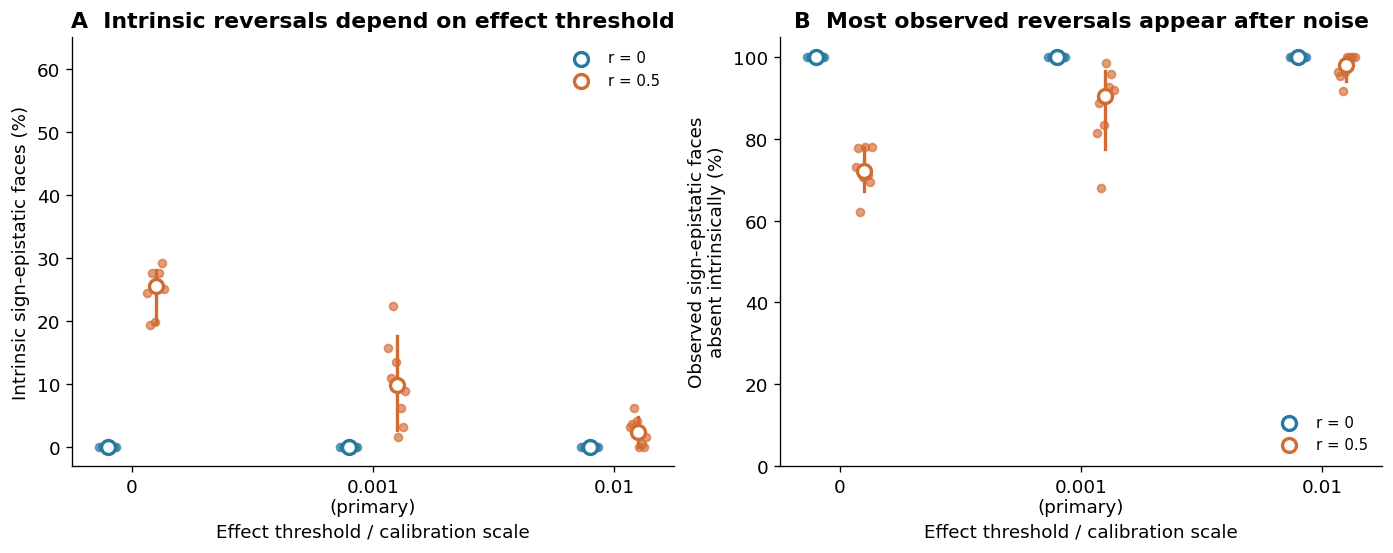

In [11]:
fig,axs=plt.subplots(1,2,figsize=(11.5,4.5),layout='constrained')
for arm,dx in [('r0',-.1),('full',.1)]:
    for i,t in enumerate(resolutions):
        g=created[(created.arm==arm)&(created.cohort=='fresh')&np.isclose(created.epsilon,t,rtol=0,atol=1e-15)]
        points(axs[0],100*g.intrinsic_sign_fraction,i+dx,colors[arm],names[arm] if i==0 else None)
        points(axs[1],100*g.observed_signs_absent_intrinsically,i+dx,colors[arm],names[arm] if i==0 else None)
for ax in axs:
    ax.set(xticks=range(3),xticklabels=['0','0.001\n(primary)','0.01'],xlabel='Effect threshold / calibration scale')
    ax.legend(frameon=False,fontsize=9,loc='lower right')
axs[0].legend(frameon=False,fontsize=9,loc='upper right')
axs[0].set(ylabel='Intrinsic sign-epistatic faces (%)',title='A  Intrinsic reversals depend on effect threshold',ylim=(-3,65))
axs[1].set(ylabel='Observed sign-epistatic faces\nabsent intrinsically (%)',title='B  Most observed reversals appear after noise',ylim=(0,105))
save(fig,'06_resolution_sensitivity')

## Interpretation
**The observation layer supplies most of the observed sign-epistatic geometry.**
At the primary threshold, fresh-seed medians are 0% → 62.5% sign-epistatic faces
for r=0 and 9.9% → 64.1% for r=0.5, compared with 65.1% in TrpB.
In the full model, 90.4% of observed sign-epistatic faces were absent intrinsically;
this is 72.3% at zero threshold and 98.3% at the coarser threshold.

**That does not mean all spectral epistasis is noise.** In the pooled fresh-cube
accounting, intrinsic sigmoid-transformed fitness supplies 91.1% of full-model
observed order-2 power, 61.3% of order-3 and 16.3% of order-4 power. Shared and
independent noise supply 72.3% and 15.7% of order-4 power, with −4.2% cross terms.
These are pooled power accounts, not median-seed fractions or identified biology.
The r=0 intrinsic map also has spectral interactions induced by its sigmoid.

The full model improves calibration loss by 26.3%, chiefly through the quantile
term. It does not consistently improve unfitted repeatable interaction metrics:
it is closer than r=0 on 2/8, 7/8 and 4/8 paired seeds for orders 2, 3 and 4,
and 3/8 for repeatable sign epistasis. No equivalence or universal superiority is
established. The all-active comparison is sparse and the near-floor stop
correction can be negative; neither resolves biological/shared-error ambiguity.

Thus the current observed model is a **structured landscape plus a substantial
random genotype-level component**. r remains an intrinsic control, but the
observed TrpB-like sign ruggedness is not shown to be governed primarily by r.
This diagnoses dependence on the observation model, not that real TrpB epistasis
is noise. Shared errors can be repeatable, and their biological origin is not
identified here. No new fit, model promotion or empirical validation is claimed.